# 02b — Baseline refit on all training rows

Takes the best configuration found by the parameter search in **02** and refits it on **all ~245k train rows outside the fixed val split** (02 used a 60k sample). Same split, same val rows → directly comparable; its val/test scores are extra inputs for stacking in 04.

**Run on Kaggle**
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. *Settings*: Accelerator **None (CPU)**.
3. *Add Input*: competition **ai-generated-text-detection-hw3-ucu-ai-2026**, and the output of **02_baseline**.
4. *Save Version → Save & Run All (Commit)*. **ETA: ~2–3 h (TF-IDF on 245k texts ≈ 40 min, model fit ≈ 1–1.5 h).**

**Copy back into the repo** (from the version's *Output* tab):
- this notebook with outputs → `notebooks/02b_baseline_full.ipynb`
- `cm_*.png` → `reports/figures/`
- keep `baseline_full_*_scores.csv` only on Kaggle (input of 04)


In [1]:
import os, glob, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SMOKE = bool(os.environ.get('SMOKE'))  # tiny local dry-run of the whole notebook; never set on Kaggle
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT.mkdir(exist_ok=True)
SEED, LABELS = 42, ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    """Locate an input file in attached Kaggle inputs (or ../data locally)."""
    for root in ['/kaggle/input', '../data', str(OUT)]:
        hits = sorted(glob.glob(f'{root}/**/{name}', recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found: attach the inputs listed at the top of this notebook')

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")  # the competition metric

def report(y_true, y_pred, title):
    """Per-class metrics + normalized confusion matrix (labels are class indices)."""
    print(f'{title}: macro-F1 = {macro_f1(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', values_format='.3f')
    plt.title(title); plt.grid(False)
    plt.savefig(OUT / f"cm_{re.sub(r'[^a-z0-9]+', '_', title.lower())}.png", dpi=120, bbox_inches='tight'); plt.show()

def f1_by(df, pred_col, by):
    return df.groupby(by).apply(lambda d: macro_f1(d.y, d[pred_col])).round(4).rename('macro_f1').to_frame().join(df[by].value_counts().rename('n'))

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
if SMOKE:
    test = test.head(300); sub = sub[sub.id.isin(test.id)]
train['y'] = train.label.map(L2I)
print(train.shape, test.shape)

(272352, 6) (25000, 4)


In [2]:
split = pd.read_csv(find('split.csv'))
train = train.merge(split, on='id', validate='1:1')
val = train[train.is_val].reset_index(drop=True)
print('val rows:', len(val), '| fixed train sample:', (train.sample_rank >= 0).sum())

val rows: 27451 | fixed train sample: 60001


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import ComplementNB
from scipy.sparse import hstack

best = pd.read_csv(find('baseline_results.csv')).iloc[0]
print('best config from 02:', best.to_dict())
MAKERS = {'LinearSVC': lambda p: LinearSVC(C=p, dual=True, random_state=SEED),
          'LogReg': lambda p: LogisticRegression(C=p, max_iter=1000, random_state=SEED),
          'ComplementNB': lambda p: ComplementNB(alpha=p),
          'SGD-modhuber': lambda p: SGDClassifier(loss='modified_huber', alpha=p, max_iter=30, random_state=SEED)}
tr = train[~train.is_val]
print('training rows:', len(tr))

best config from 02: {'model': 'LogReg', 'param': 10.0, 'features': 'word+char', 'val_macro_f1': 0.8796, 'sec': 490}
training rows: 244901


In [4]:
# same vectorizer settings as 02; float32 halves memory for 245k documents
VEC = {'word': dict(ngram_range=(1, 2), min_df=3, max_features=300_000, sublinear_tf=True),
       'char': dict(analyzer='char_wb', ngram_range=(3, 5), min_df=5, max_features=300_000, sublinear_tf=True, lowercase=False)}
vecs = {n: TfidfVectorizer(dtype=np.float32, **VEC[n]) for n in best.features.split('+')}
def featurize(texts, fit=False):
    parts = [(v.fit_transform if fit else v.transform)(texts) for v in vecs.values()]
    return hstack(parts).tocsr() if len(parts) > 1 else parts[0]
t = time.time()
Xtr = featurize(tr.text, fit=True); Xva = featurize(val.text)
print(f'features {Xtr.shape} in {(time.time() - t) / 60:.0f} min')

features (244901, 600000) in 26 min


fit in 39 min
train macro-F1 (20k rows) 0.9846  vs  val 0.8984
02 baseline on 60k sample: val 0.8796
Baseline full-data val: macro-F1 = 0.8984
              precision    recall  f1-score   support

       human     0.8115    0.8864    0.8473      6723
          ai     0.9858    0.9915    0.9886     12239
      fusion     0.8974    0.8244    0.8593      8489

    accuracy                         0.9141     27451
   macro avg     0.8982    0.9007    0.8984     27451
weighted avg     0.9158    0.9141    0.9140     27451



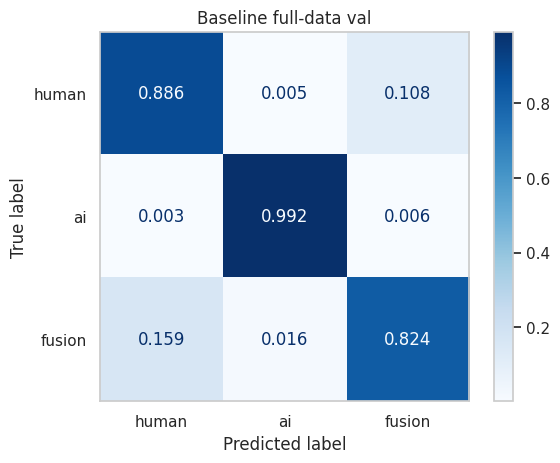

,macro_f1,n
domain,,
arxiv_papers,0.8980,1378
blog_authorship_corpus,0.7751,4004
bundestag,0.9199,5343
cnn_news,0.9423,4436
euro_court_cases,0.9230,2776
gutenberg,0.8168,723
house_of_commons,0.8974,3117
student_essays,0.9114,5674


In [5]:
t = time.time()
clf = MAKERS[best.model](best.param).fit(Xtr, tr.y)
print(f'fit in {(time.time() - t) / 60:.0f} min')
scores = lambda X: clf.decision_function(X) if hasattr(clf, 'decision_function') else clf.predict_log_proba(X)
val['pred'] = clf.predict(Xva)
sub_i = np.random.RandomState(SEED).choice(len(tr), min(20_000, len(tr)), replace=False)
print(f'train macro-F1 (20k rows) {macro_f1(tr.y.values[sub_i], clf.predict(Xtr[sub_i])):.4f}  vs  val {macro_f1(val.y, val.pred):.4f}')
b60 = val[['id', 'y']].merge(pd.read_csv(find('baseline_val_scores.csv')), on='id')
print(f'02 baseline on 60k sample: val {macro_f1(b60.y, b60[[f"base_{l}" for l in LABELS]].values.argmax(1)):.4f}')
report(val.y, val.pred, 'Baseline full-data val')
display(f1_by(val, 'pred', 'domain'))

**Observations.** The same configuration on all 245k rows reaches **0.898** (+0.019 over the 60k sample), and the train–val gap shrinks (0.985 vs 0.898), so the TF-IDF model was data-limited. Both hard classes improve (human F1 0.847, fusion 0.859). Blogs are still the weakest domain (0.78). Gutenberg drops (0.889 → 0.817), but it has only 723 val rows, nearly all ai, so its per-domain macro-F1 depends on a few dozen human/fusion texts.

In [6]:
cols = [f'basef_{l}' for l in LABELS]
pd.DataFrame(scores(Xva), columns=cols).assign(id=val.id.values).to_csv(OUT / 'baseline_full_val_scores.csv', index=False)
del Xtr
te = scores(featurize(test.text))
pd.DataFrame(te, columns=cols).assign(id=test.id.values).to_csv(OUT / 'baseline_full_test_scores.csv', index=False)
pred = pd.DataFrame({'id': test.id, 'label': np.array(LABELS)[te.argmax(1)]})
submission = sub[['id']].merge(pred, on='id', how='left')
assert len(submission) == len(sub) and submission.label.isin(LABELS).all()
submission.to_csv(OUT / 'submission_baseline_full.csv', index=False)
print(submission.label.value_counts(normalize=True).round(3))

label
ai        0.516
human     0.265
fusion    0.218
Name: proportion, dtype: float64
